### Notebook to test different elements of the script 

🎯 The goal is to reproduce the figures from *Jiang and Litwin-Kumar (2021)*.

‼️**IMPORTANT**: If you are running this notebook for the first time, please make sure to install the required packages by running the following lines in your terminal:
1. Activate your environment: 
* Windows (PowerShell): ``.venv\Scripts\Activate.ps1``
* macOS / Linux (Bash): ``source .venv/bin/activate``
2. Install the requirements: ``python -m pip install -r requirements.txt``

🚩 @ TODO : might want to add a step to create environment, also the "activate your environment" might vary if user is using conda or virtual environment... need to verify.

In [1]:
## Imports
import numpy as np
import torch
import matplotlib.pyplot as plt
from test_modules.plasticity import *
import definemodel as model_parameters

### Definition of all parameters and their biological interpretation

#### Fig. 1. B and 1. C - Dopamine neuron-gated plasticity rule for $W_{KC\rightarrow MBON}$

This figure shows $\Delta W_{KC\rightarrow MBON}$ the change in weights from an example *j-th* KC to *i-th* MBON neuron as a function of $\Delta W$ the time difference between **Kenyon cell** activation and **dopamine neuron** activation : $\Delta T = t_{DAN} - t_{KC}$. 

* If $\Delta T > 0$, we have **forward pairing** (KC first, then DAN): there is an increasingly larger positive change in weights until $T=0$; if the KC activation is prior than 10 seconds before the DAN activation, then the weight difference tends to zero and no association is being formed, while smaller negative time difference correspond to large positive weight differences. 
* If $\Delta T < 0$, we have **backward pairing** (DAN first, then KC): a negative weight difference that starts at the maximum magnitude but at a negative value and tends to zero as the time difference increases, which makes for no association being created.

To track the change in $W_{KC \rightarrow MBON}$ we need to look at this part of the article *(page 5)*:

>We therefore augmented our networks with a model of this plasticity by assuming that each element of $W_{KC \rightarrow MBON}$ is a dynamic quantity that tracks the variables $w_{ij}$ (with a time constant of $\tau_W$ = 5 s). These variables, which determine the strength of the connection from the jth Kenyon cell to the ith output neuron, obey the following update rule:
> $$ \frac{dw_{ij}(t)}{dt} = \bar{r}_i^{DAN}(t)r_j(t) - \bar{r}_j^{KC}(t)r_i^{DAN}(t)$$
> Each element of $W_{KC \rightarrow MBON}$ is initially set to its maximum value of 0.05 and subsequently updated according to
> $$ \tau_W \frac{dW^{KC \rightarrow MBON}_{ij}(t)}{dt}= -W^{KC \rightarrow MBON}_{ij}(t) + w_{ij}(t)$$

##### Fig. 1. B

In [17]:
# Construct the array of time differences between pulses of activation
dT_win_start = -10 # (in seconds)
dT_win_end = 10 # (in seconds)
dT_win_step = 0.1 # (in seconds)
dT_win_num = int((dT_win_end - dT_win_start)/dT_win_step) + 1
dT_array = torch.linspace(start=dT_win_start, end=dT_win_end, steps=dT_win_num)

# Define time range of the experience
time_range_end = 60 # (in seconds)
#dt = model_parameters.dt # (in seconds)
dt=0.1
time_range = torch.arange(0, time_range_end, dt)

# Import the model parameters
tau = model_parameters.tau
tauw = model_parameters.tauw
wmax = model_parameters.wmax
stdpfac = model_parameters.stdpfac

# For this figure, we simulate only one KC, one MBON, and one DAN neuron
n_kc = 1
n_mbon = 1
n_dan = 1

# Define the batch size as 1
batch_size = 1

wmax_factor = 0.5 # Factor to scale the maximum weight for plotting purposes

# Initialize the pulses and weights
pulse_amp = 0.5
pulse_kc = torch.zeros((n_kc, len(time_range), batch_size))
pulse_dan = torch.zeros((n_dan, len(time_range), batch_size))

# The DAN pulse is kept as a reference and we sweep through the KC pulse
t_dan_init = time_range_end//4 # (in seconds)
pulse_duration = 1 # (in seconds)
pulse_dan[:, int(t_dan_init/dt):int((t_dan_init + pulse_duration)/dt), :] = pulse_amp

# Create array to store all dW values for each time difference
dW_tot = torch.zeros((len(dT_array), n_mbon, n_kc, batch_size))


In [18]:
# Run an experience during time_range for each dT in dT_array
for dT_idx, dT in enumerate(dT_array):
    # Reset the KC pulse and weights for each dT
    pulse_kc = torch.zeros((n_kc, len(time_range), batch_size))
    W_init = wmax_factor*wmax*torch.ones((n_mbon, n_kc, batch_size))
    W = W_init.clone()

    # (Re)create the KC pulse for current dT
    t_kc_init = t_dan_init - dT.item()
    pulse_kc[:, int(t_kc_init/dt):int((t_kc_init + pulse_duration)/dt), :] = pulse_amp

    # Initialize the filtered firing rates for KC and DAN neurons
    rbar_kc = torch.zeros((n_kc, batch_size))
    rbar_dan = torch.zeros((n_dan, batch_size))
    
    # Run the experience for the current dT
    for t_idx, t in enumerate(time_range):
        r_dan = pulse_dan[:, t_idx]
        r_kc = pulse_kc[:, t_idx]
        W, rbar_kc, rbar_dan = update_kc_mbon_weights(W, r_kc, r_dan, rbar_kc, rbar_dan, 
                                                    dt=dt,
                                                    tau=tau,
                                                    tauw=tauw,
                                                    wmax=wmax,
                                                    stdpfac=stdpfac
                                                    )
    dW_tot[dT_idx] = W - W_init 



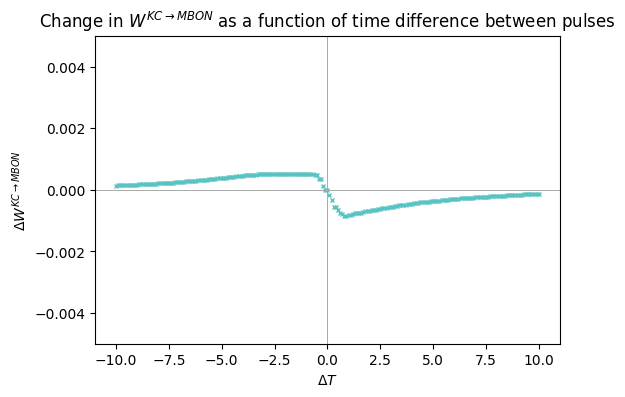

In [19]:
# Plot dW as a function of dT
plt.figure(figsize=(6, 4))
plt.plot(dT_array, dW_tot[:, 0, 0, 0], 'x', markersize=3, color='#59C3C3')
plt.ylim([-0.005, 0.005]) # arbitrary lol
plt.title(r'Change in $W^{KC \rightarrow MBON}$ as a function of time difference between pulses')
plt.xlabel(r'$\Delta T$')
plt.ylabel(r'$\Delta W^{KC \rightarrow MBON}$')
plt.axhline(0, color='darkgrey', linestyle='-', linewidth=0.7)
plt.axvline(0, color='darkgrey', linestyle='-', linewidth=0.7)

# Idea : plot also four pulses, one where dT = -10, one where dT = -5, one where dT = 5, and one where dT = 10.

If we take out the bounds on $\Delta W$...

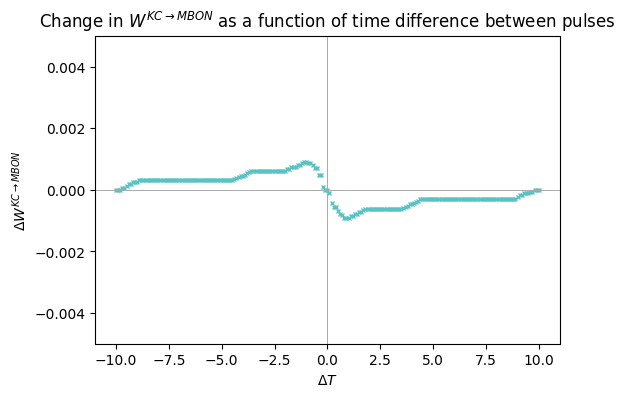

In [20]:
wmax=1000
# Run an experience during time_range for each dT in dT_array
for dT_idx, dT in enumerate(dT_array):
    # Reset the KC pulse and weights for each dT
    pulse_kc = torch.zeros((n_kc, len(time_range), batch_size))
    W_init = wmax_factor*wmax*torch.ones((n_mbon, n_kc, batch_size))
    W = W_init.clone()

    # (Re)create the KC pulse for current dT
    t_kc_init = t_dan_init - dT.item()
    pulse_kc[:, int(t_kc_init/dt):int((t_kc_init + pulse_duration)/dt), :] = pulse_amp

    # Initialize the filtered firing rates for KC and DAN neurons
    rbar_kc = torch.zeros((n_kc, batch_size))
    rbar_dan = torch.zeros((n_dan, batch_size))
    
    # Run the experience for the current dT
    for t_idx, t in enumerate(time_range):
        r_dan = pulse_dan[:, t_idx]
        r_kc = pulse_kc[:, t_idx]
        W, rbar_kc, rbar_dan = update_kc_mbon_weights(W, r_kc, r_dan, rbar_kc, rbar_dan, 
                                                    dt=dt,
                                                    tau=tau,
                                                    tauw=tauw,
                                                    wmax=wmax,
                                                    stdpfac=stdpfac
                                                    )
    dW_tot[dT_idx] = W - W_init 

# Plot dW as a function of dT
plt.figure(figsize=(6, 4))
plt.plot(dT_array, dW_tot[:, 0, 0, 0], 'x', markersize=3, color='#59C3C3')
plt.ylim([-0.005, 0.005]) # arbitrary lol
plt.title(r'Change in $W^{KC \rightarrow MBON}$ as a function of time difference between pulses')
plt.xlabel(r'$\Delta T$')
plt.ylabel(r'$\Delta W^{KC \rightarrow MBON}$')
plt.axhline(0, color='darkgrey', linestyle='-', linewidth=0.7)
plt.axvline(0, color='darkgrey', linestyle='-', linewidth=0.7)


In [21]:
# Reset the parameter
wmax = model_parameters.wmax

Small test with different values of $\Delta W^{KC \rightarrow MBON}$, pulse amplitude, and pulse duration.

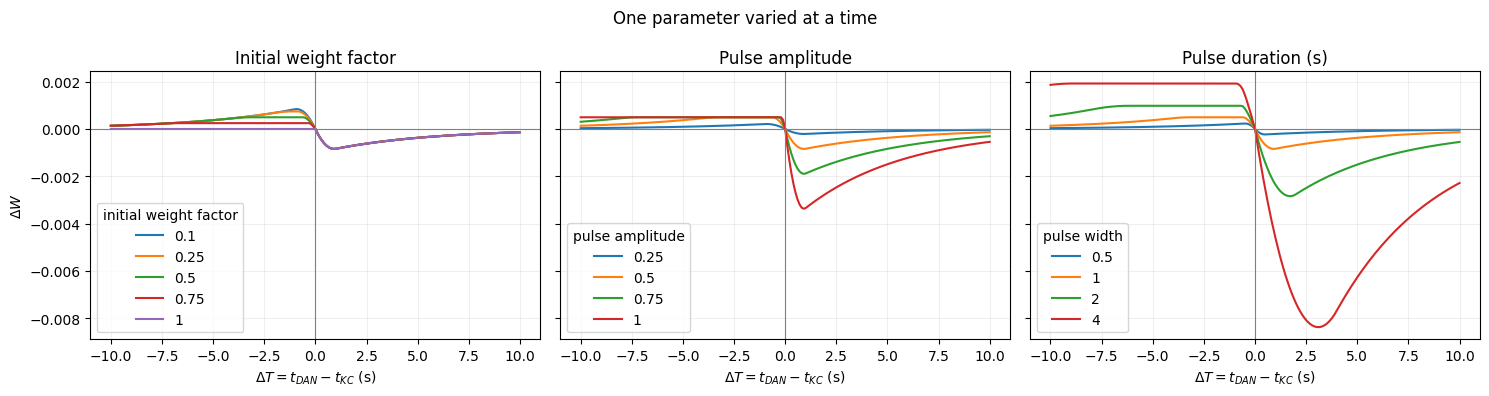

In [22]:
# One-factor-at-a-time sensitivity analysis for the pulse-pairing curve.
# Each panel varies one setting while holding the other two at their values above.
def run_pulse_pairing_curve(dT_values, *, initial_weight_factor, pulse_amplitude, pulse_width):
    curve = torch.zeros(len(dT_values))
    dan_start = round(t_dan_init / dt)
    dan_end = round((t_dan_init + pulse_width) / dt)

    for dT_idx, dT in enumerate(dT_values):
        pulse_kc_trial = torch.zeros((n_kc, len(time_range), batch_size))
        pulse_dan_trial = torch.zeros((n_dan, len(time_range), batch_size))

        # Delta T is defined as t_DAN - t_KC.
        t_kc_init = t_dan_init - dT.item()
        kc_start = round(t_kc_init / dt)
        kc_end = round((t_kc_init + pulse_width) / dt)
        pulse_kc_trial[:, kc_start:kc_end, :] = pulse_amplitude
        pulse_dan_trial[:, dan_start:dan_end, :] = pulse_amplitude

        W_initial = (initial_weight_factor * wmax) * torch.ones(
            (n_mbon, n_kc, batch_size)
        )
        W_trial = W_initial.clone()
        rbar_kc_trial = torch.zeros((n_kc, batch_size))
        rbar_dan_trial = torch.zeros((n_dan, batch_size))

        for t_idx in range(len(time_range)):
            W_trial, rbar_kc_trial, rbar_dan_trial = update_kc_mbon_weights(
                W_trial,
                pulse_kc_trial[:, t_idx, :],
                pulse_dan_trial[:, t_idx, :],
                rbar_kc_trial,
                rbar_dan_trial,
                dt=dt,
                tau=tau,
                tauw=tauw,
                wmax=wmax,
                stdpfac=stdpfac,
            )

        curve[dT_idx] = (W_trial - W_initial)[0, 0, 0]

    return curve


# Include the current setting in each sweep as its reference curve.
reference = {
    "initial_weight_factor": wmax_factor,
    "pulse_amplitude": pulse_amp,
    "pulse_width": pulse_duration,
}
sweeps = [
    ("Initial weight factor", "initial_weight_factor", [0.1, 0.25, 0.5, 0.75, 1.0]),
    ("Pulse amplitude", "pulse_amplitude", [0.25, 0.5, 0.75, 1.0]),
    ("Pulse duration (s)", "pulse_width", [0.5, 1.0, 2.0, 4.0]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
dT_plot = dT_array.detach().cpu().numpy()

for ax, (title, varied_parameter, values) in zip(axes, sweeps):
    for value in values:
        settings = reference.copy()
        settings[varied_parameter] = value
        curve = run_pulse_pairing_curve(dT_array, **settings)
        ax.plot(dT_plot, curve.detach().cpu().numpy(), label=f"{value:g}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel(r"$\Delta T = t_{DAN} - t_{KC}$ (s)")
    ax.grid(alpha=0.2)
    ax.legend(title=varied_parameter.replace("_", " "))

axes[0].set_ylabel(r"$\Delta W$")
fig.suptitle("One parameter varied at a time")
fig.tight_layout()


##### Fig. 1. C

In [26]:
# Helper function to plot pulse of KC and DAN neurons
def plot_pulse(time_range, pulse_KC, pulse_DAN, title, ax):
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 4))
    axes[0].plot(time_range, pulse_KC[0, :, 0], label="KC", color="#59C3C3")
    axes[1].plot(time_range, pulse_DAN[0, :, 0], label="DAN", color="#E63946")
    for axis in axes:
                axis.set_xlabel("Time (s)")
                axis.set_ylabel("Amplitude")
                axis.grid(alpha=0.2)
                axis.legend()
    plt.tight_layout()


# Helper function to plot dW as a function of time
def plot_dW(time_range, dW_temp, dT_idx, title, ax):
    ax.plot(time_range, dW_temp[dT_idx, :, 0, 0, 0], "x", markersize=3, color="k")
    #ax.set_ylim([-0.005, 0.005])  # arbitrary lol
    ax.set_title(title)
    ax.set_xlabel(r"$\Delta T$")
    ax.set_ylabel(r"$\Delta W^{KC \rightarrow MBON}$")
    ax.axhline(0, color="darkgrey", linestyle="-", linewidth=0.7)
    ax.axvline(0, color="darkgrey", linestyle="-", linewidth=0.7)

In [24]:
dW_tot.shape

torch.Size([201, 1, 1, 1])

C:\Users\Bruna\AppData\Local\Temp\ipykernel_7020\4093082388.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 4))


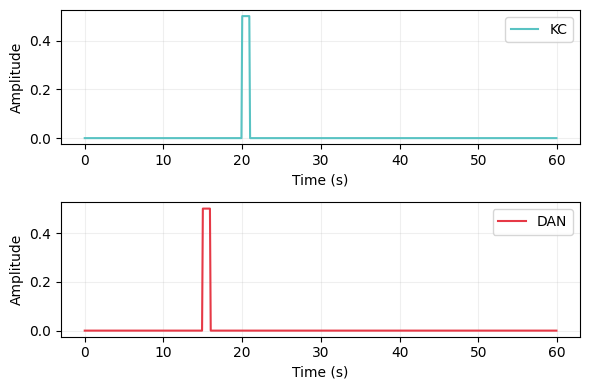

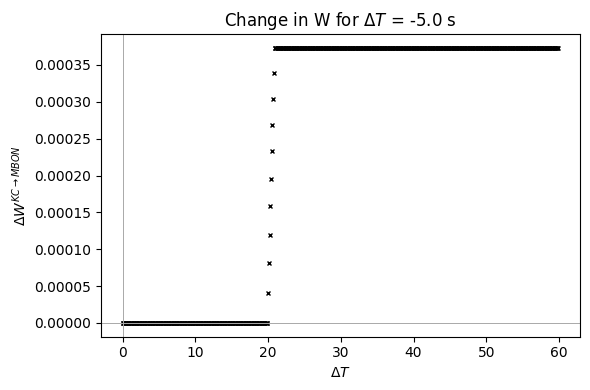

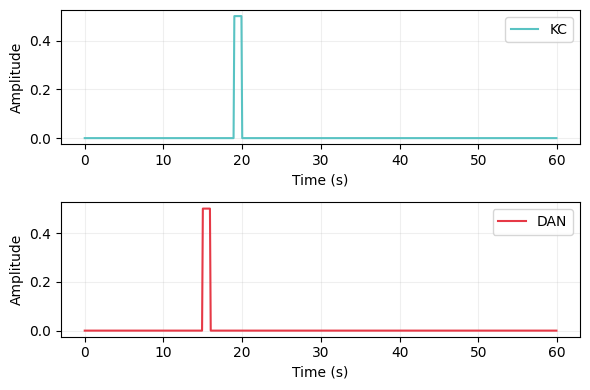

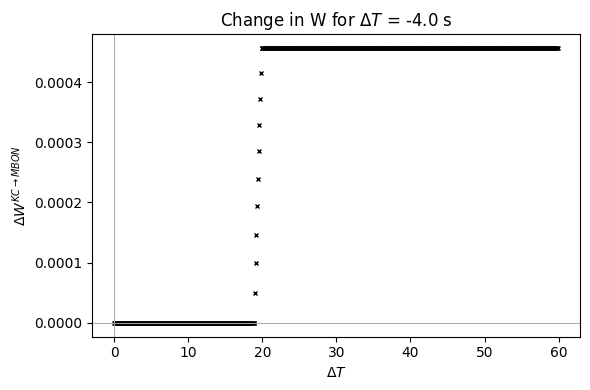

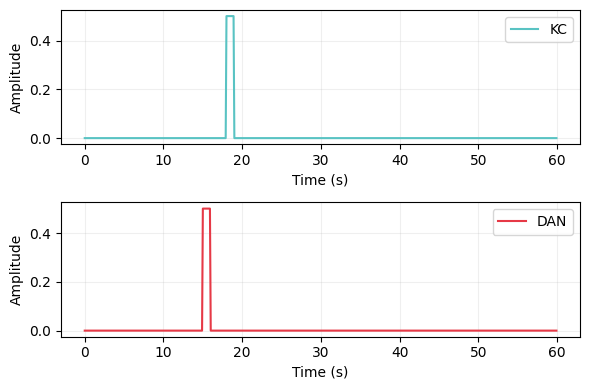

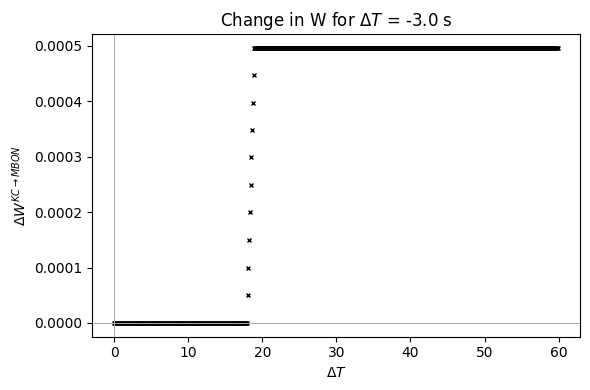

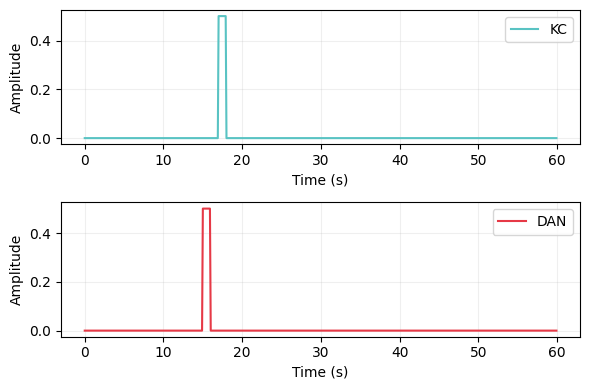

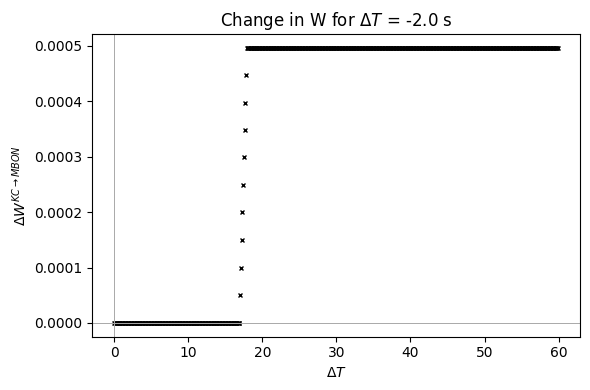

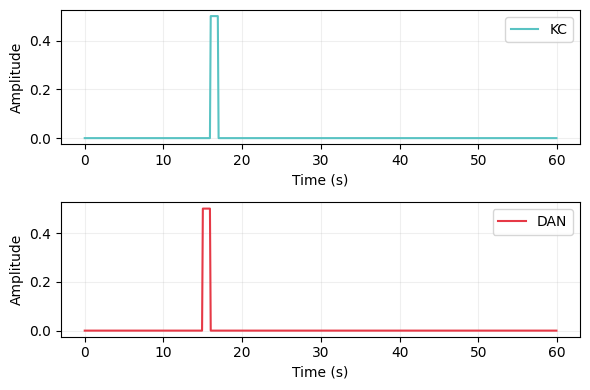

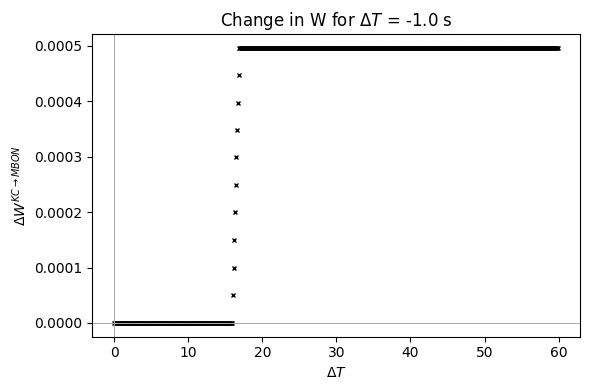

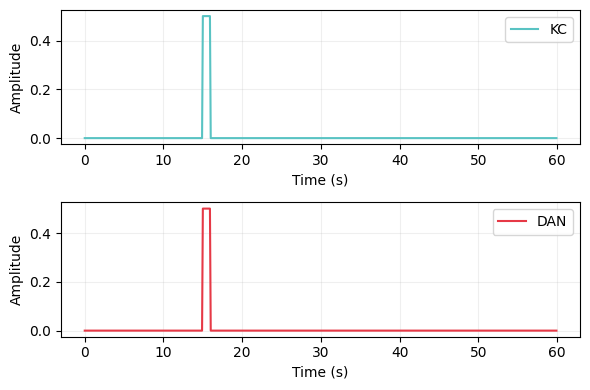

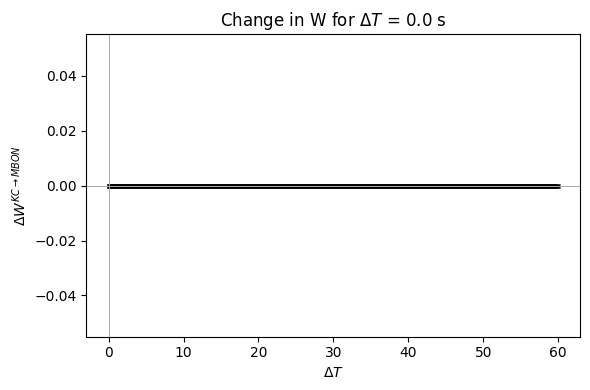

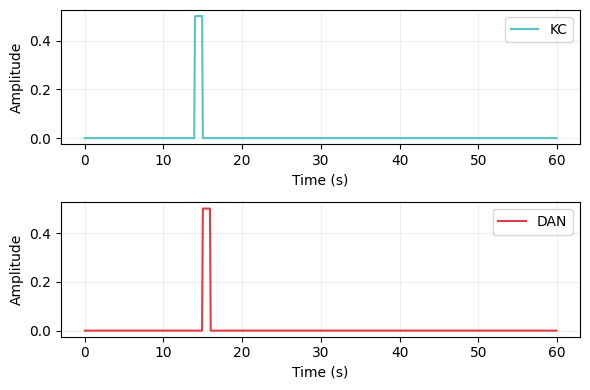

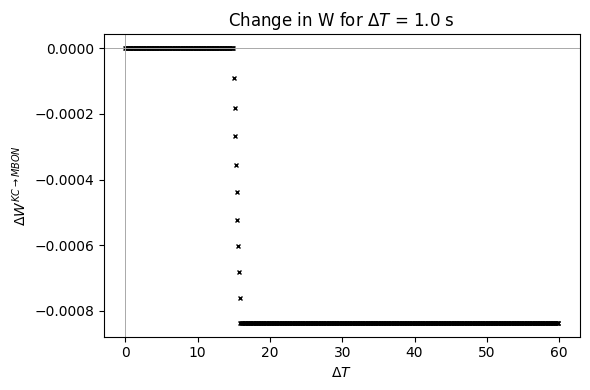

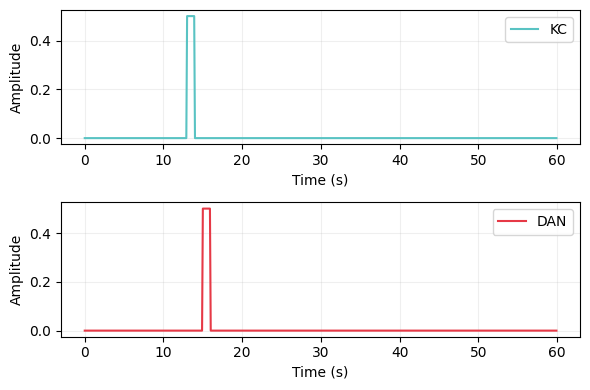

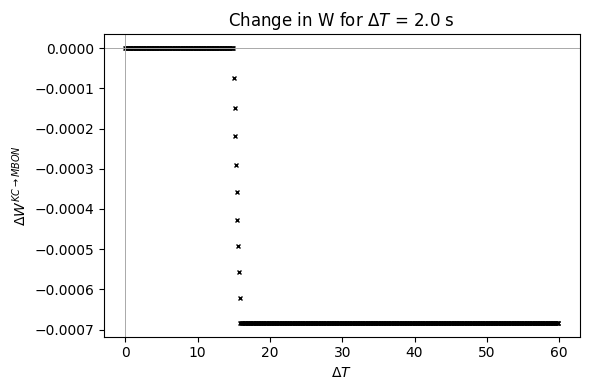

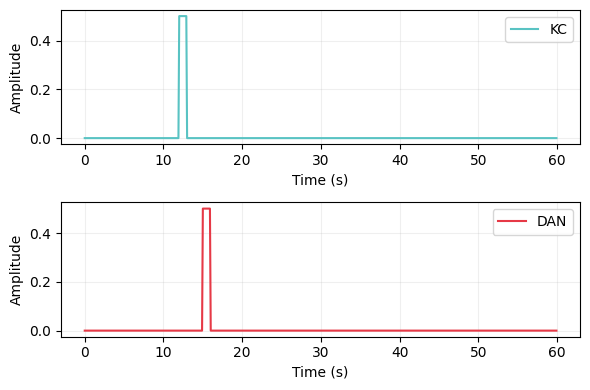

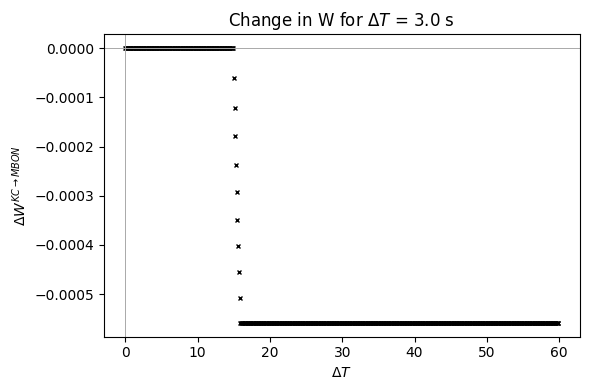

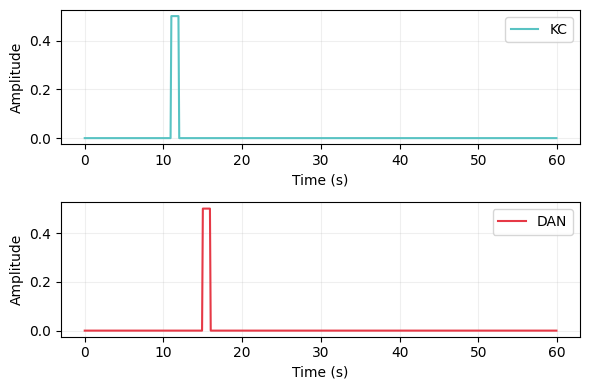

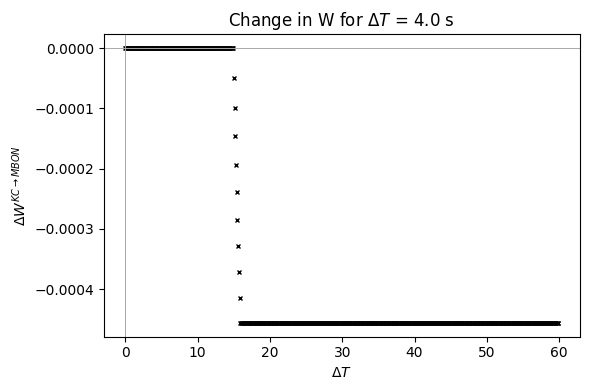

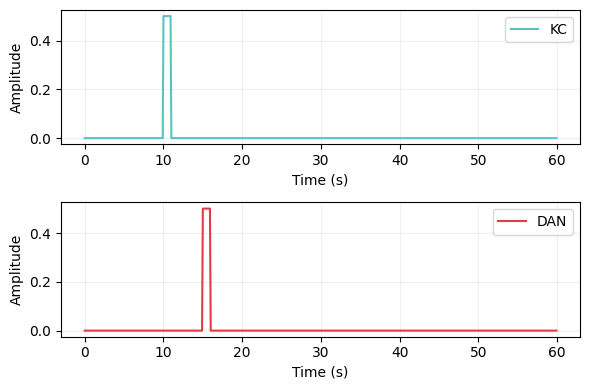

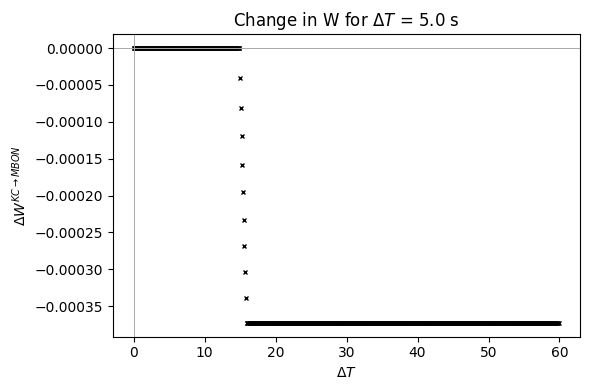

In [27]:
dT_array_sample = torch.linspace(start=-5,end=5, steps=11)
dW_temp = torch.zeros((len(dT_array_sample), len(time_range), n_mbon, n_kc, batch_size))

# Run an experience during time_range for each dT in dT_array
for dT_idx, dT in enumerate(dT_array_sample):
    # Reset the KC pulse and weights for each dT
    pulse_kc = torch.zeros((n_kc, len(time_range), batch_size))
    W_init = wmax_factor*wmax*torch.ones((n_mbon, n_kc, batch_size))
    W = W_init.clone()

    # (Re)create the KC pulse for current dT
    t_kc_init = t_dan_init - dT.item()
    pulse_kc[:, int(t_kc_init/dt):int((t_kc_init + pulse_duration)/dt), :] = pulse_amp

    # Initialize the filtered firing rates for KC and DAN neurons
    rbar_kc = torch.zeros((n_kc, batch_size))
    rbar_dan = torch.zeros((n_dan, batch_size))

    # Plot the pulses for the current dT
    plot_pulse(time_range, pulse_kc, pulse_dan, f"Pulse for dT = {dT.item()} s", ax=None)

    # Run the experience for the current dT
    for t_idx, t in enumerate(time_range):
        r_dan = pulse_dan[:, t_idx]
        r_kc = pulse_kc[:, t_idx]
        W, rbar_kc, rbar_dan = update_kc_mbon_weights(W, r_kc, r_dan, rbar_kc, rbar_dan, 
                                                    dt=dt,
                                                    tau=tau,
                                                    tauw=tauw,
                                                    wmax=wmax,
                                                    stdpfac=stdpfac
                                                    )

        dW_temp[dT_idx, t_idx] = W - W_init

    # Plot dW as a function of dT for the current dT
    fig_dW, ax_dW = plt.subplots(figsize=(6, 4))
    plot_dW(time_range, dW_temp, dT_idx, f"Change in W for $\Delta T$ = {dT.item()} s", ax_dW
    )
    fig_dW.tight_layout()


*Observation:* To obtain nice curves, we need to reduce `dt` to 0.1 instead of 0.5 as in the parameters from the methods. Furthermore, we obtain curves on Fig. 1. C that look much more like step functions than like the ones drawn in the article.

#### Fig. 3

# Initialize Wrecur , 

In [4]:
%matplotlib inline

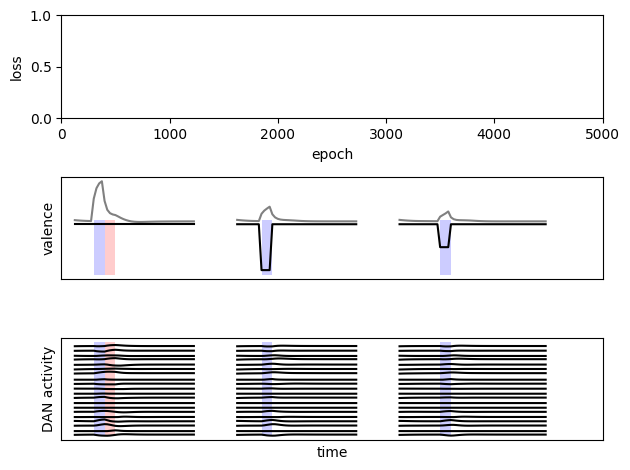

0%,  1.35 seconds

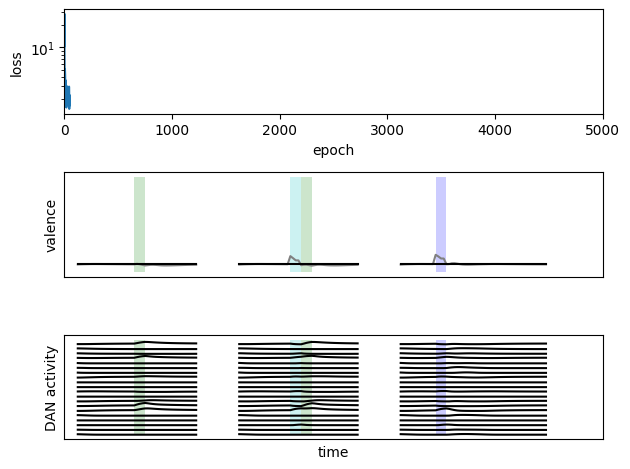

1%,  46.17 seconds

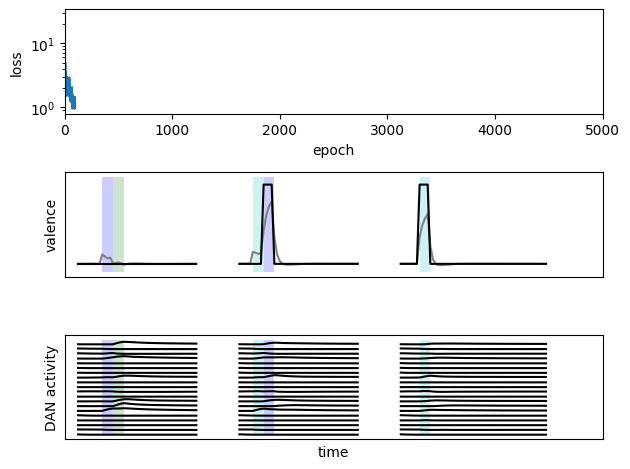

2%,  52.39 seconds

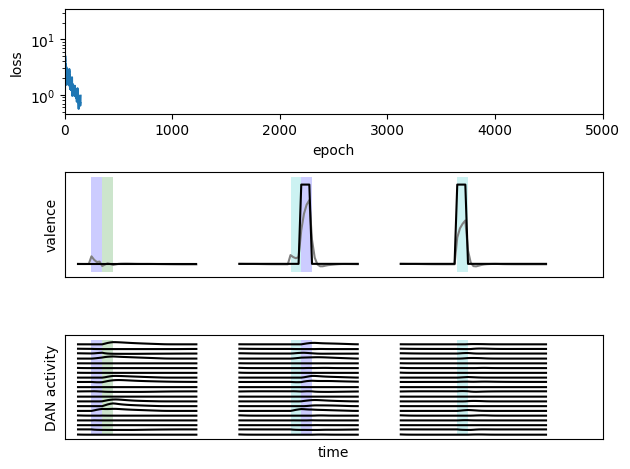

3%,  57.14 seconds

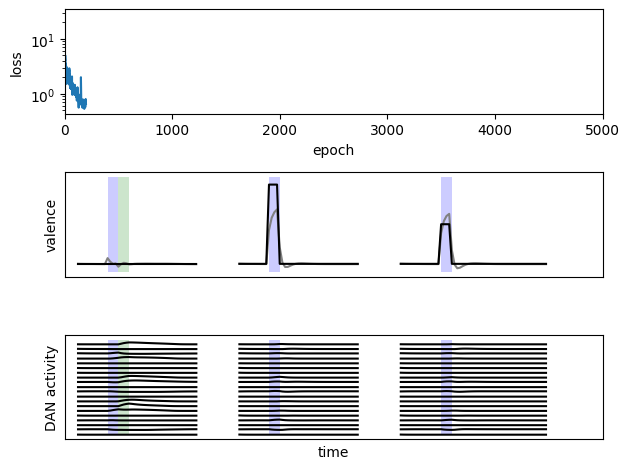

4%,  54.23 seconds

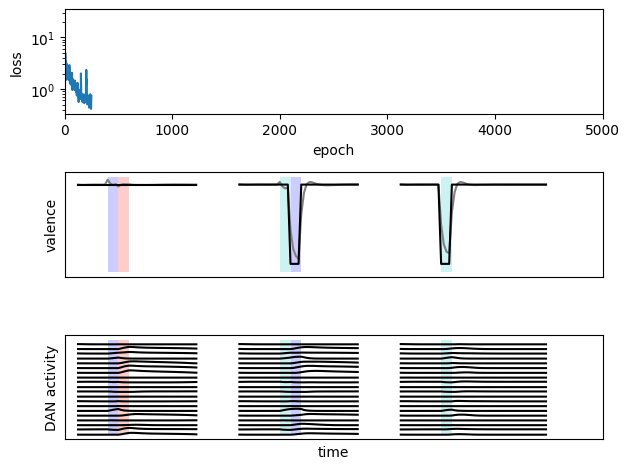

5%,  55.66 seconds

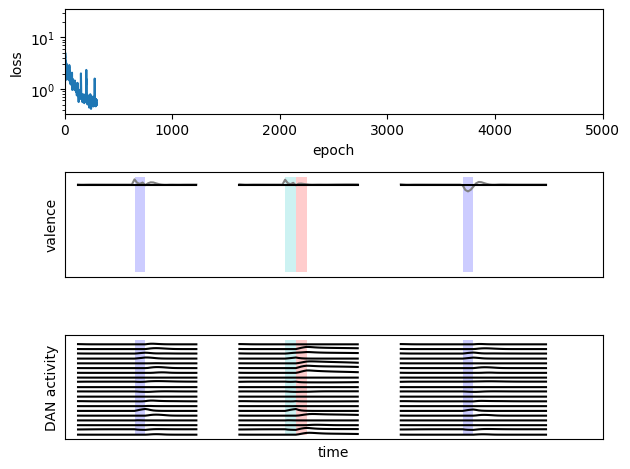

6%,  55.19 seconds

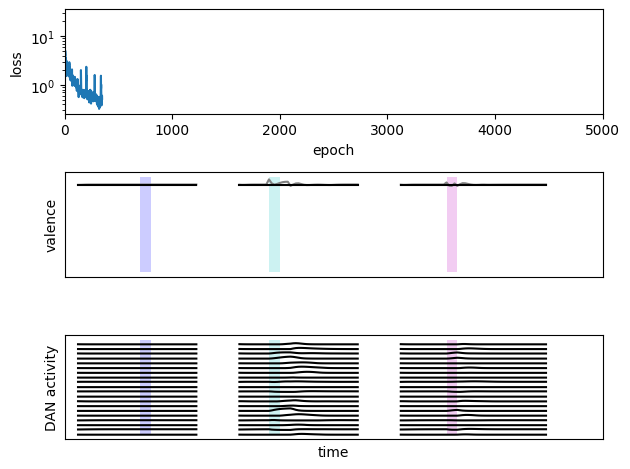

7%,  53.75 seconds

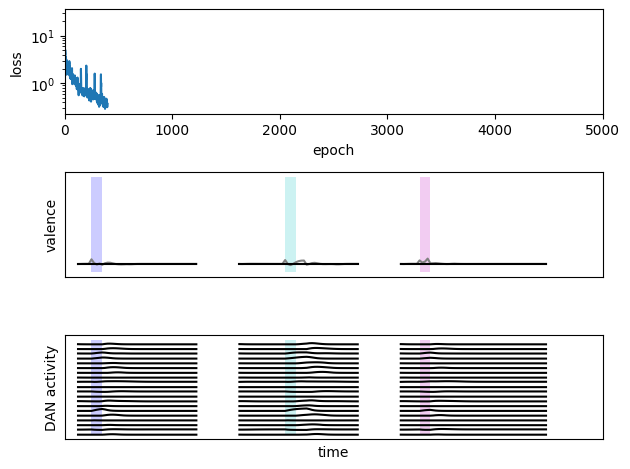

8%,  54.69 seconds

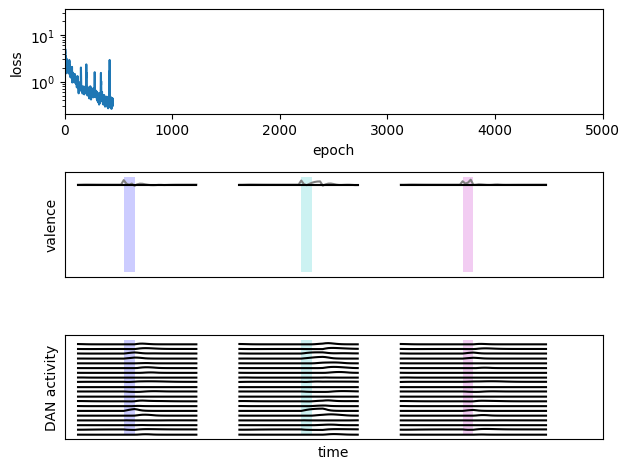

9%,  55.09 seconds

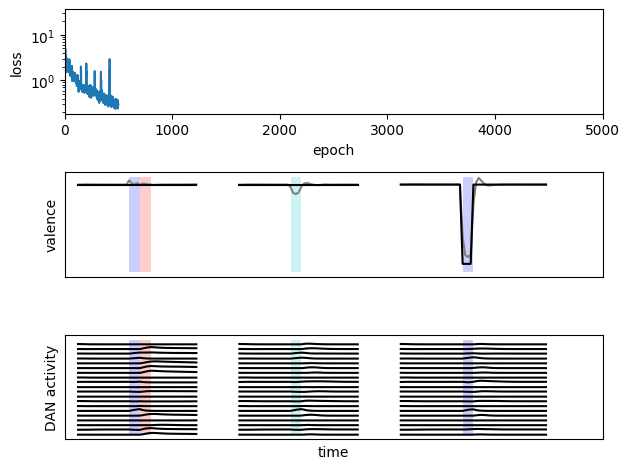

10%,  53.73 seconds

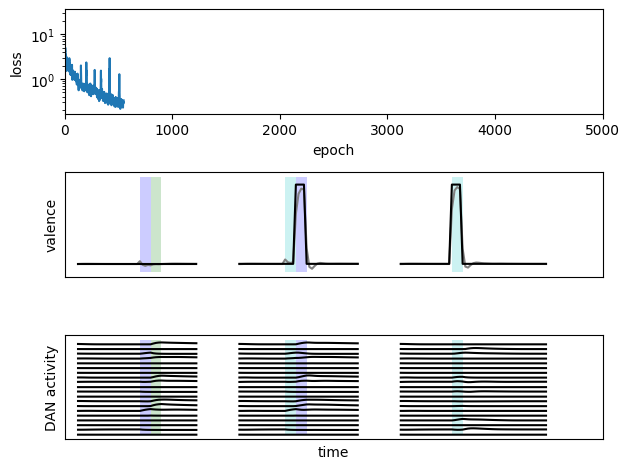

11%,  56.31 seconds

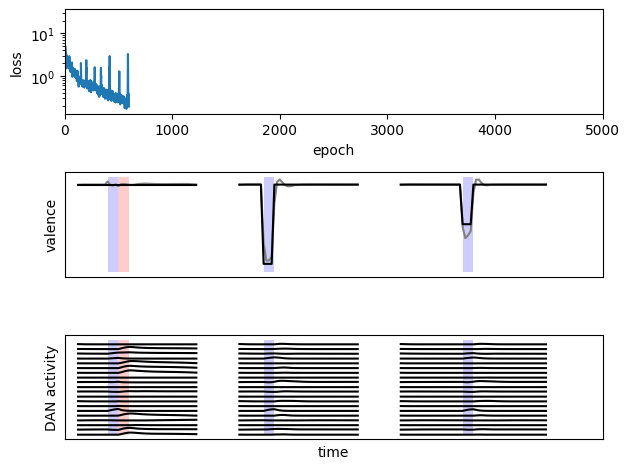

12%,  56.24 seconds

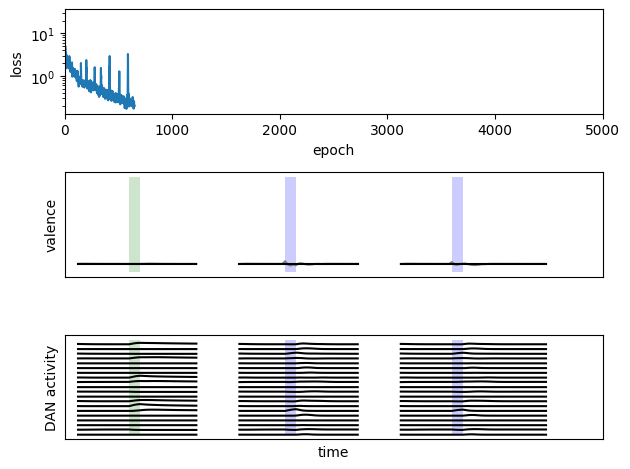

13%,  55.3 seconds

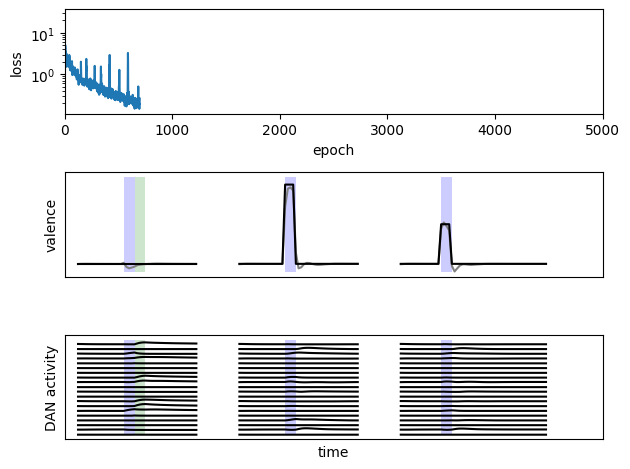

14%,  57.3 seconds

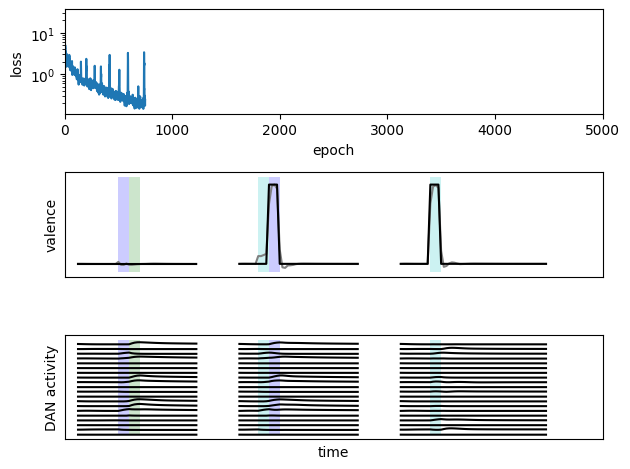

15%,  55.24 seconds

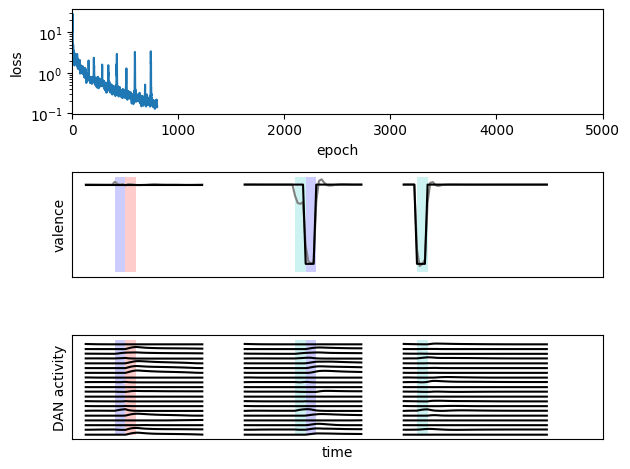

16%,  54.29 seconds

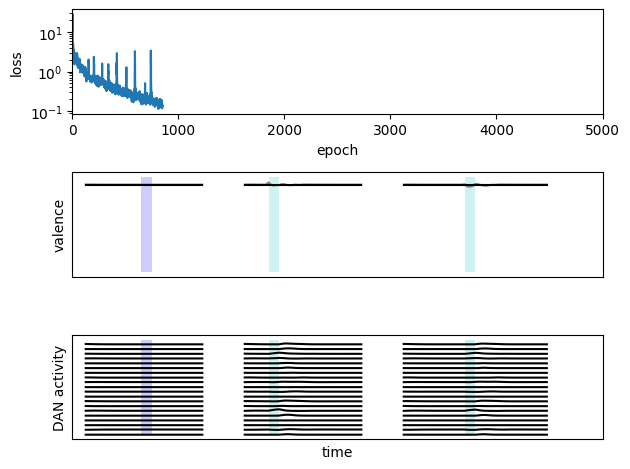

17%,  63.02 seconds

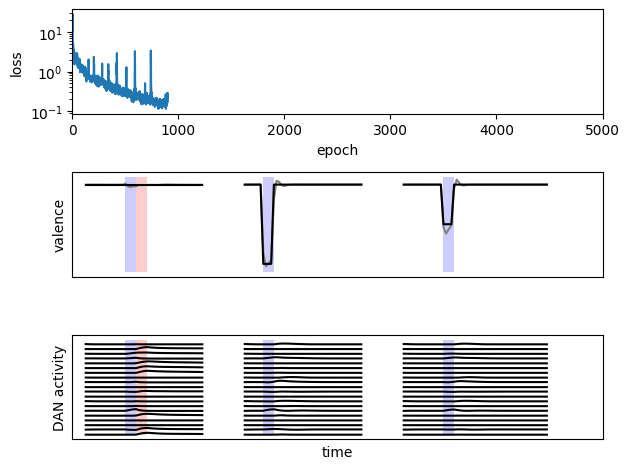

18%,  51.92 seconds

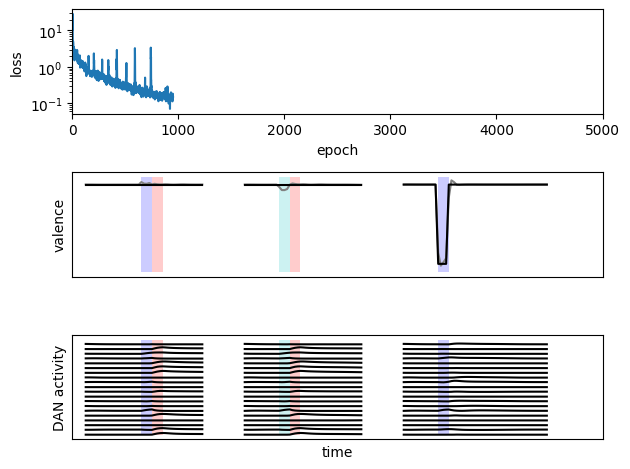

19%,  59.14 seconds

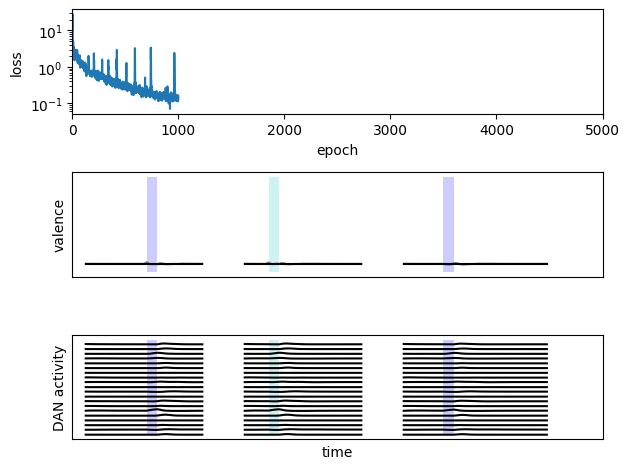

20%,  72.34 seconds

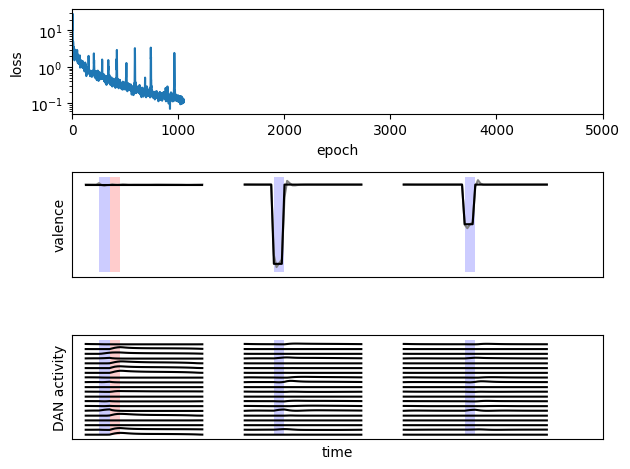

21%,  61.66 seconds

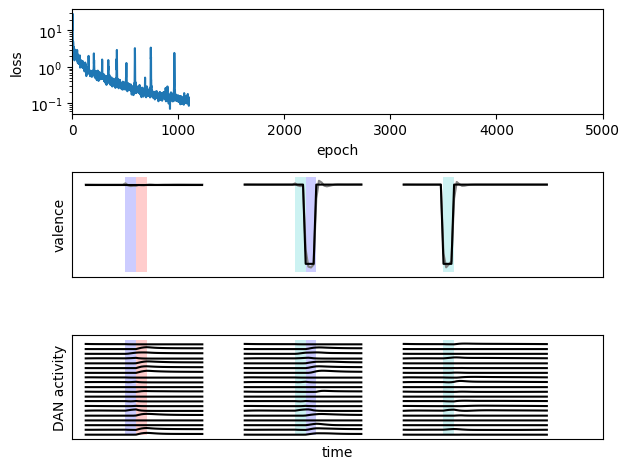

22%,  51.98 seconds

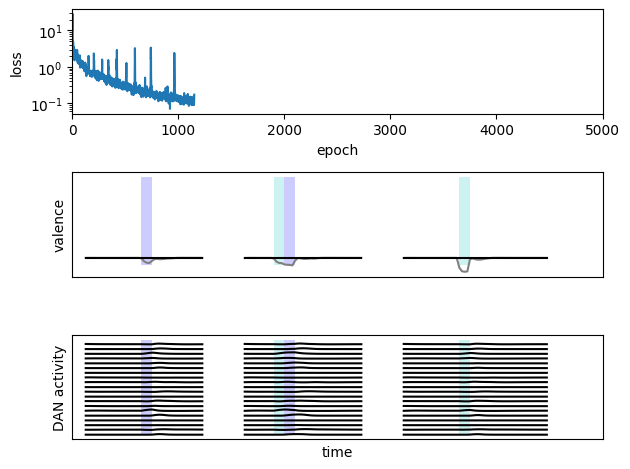

23%,  50.75 seconds

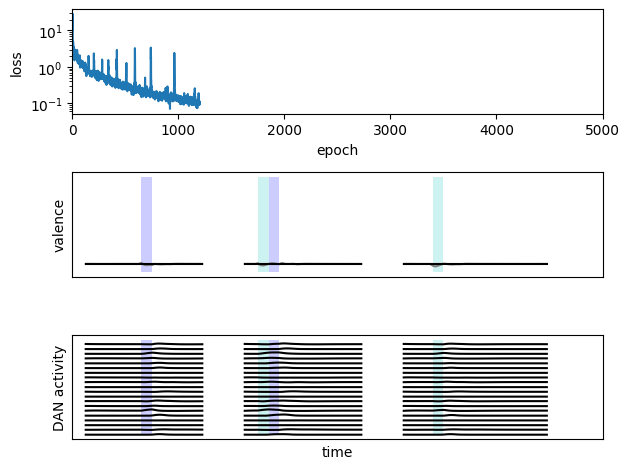

24%,  66.09 seconds

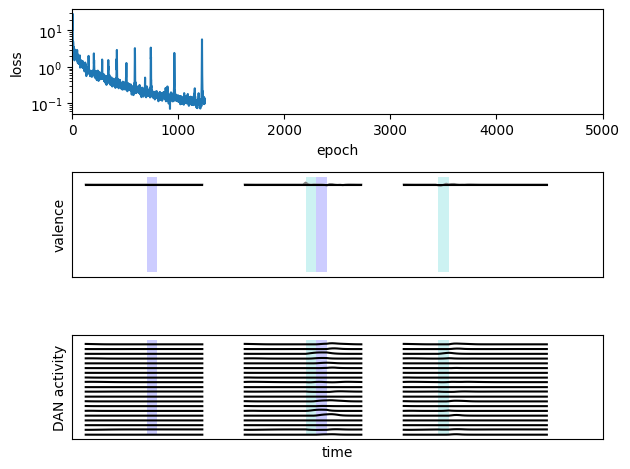

25%,  97.7 seconds

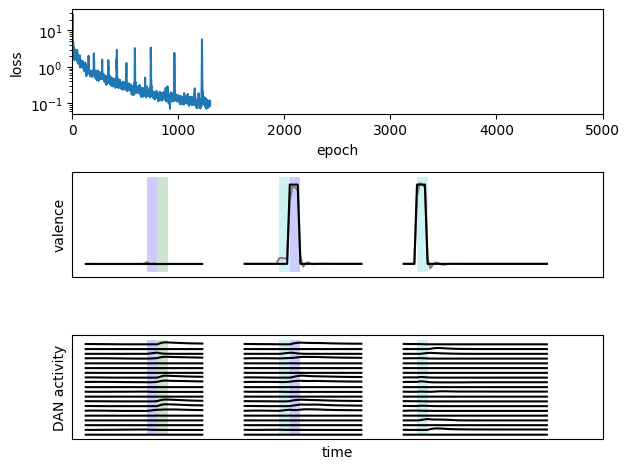

26%,  66.38 seconds

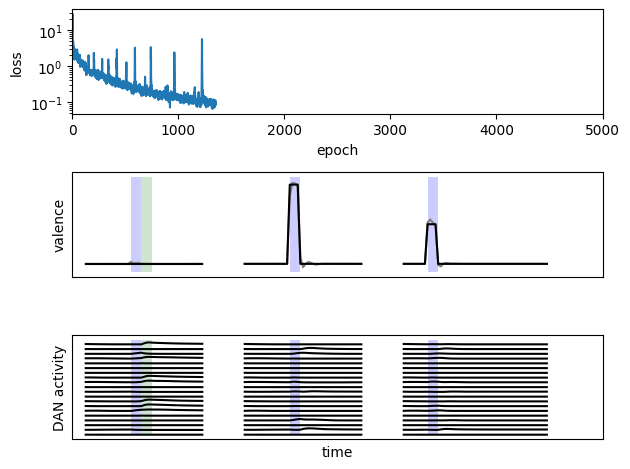

27%,  53.5 seconds

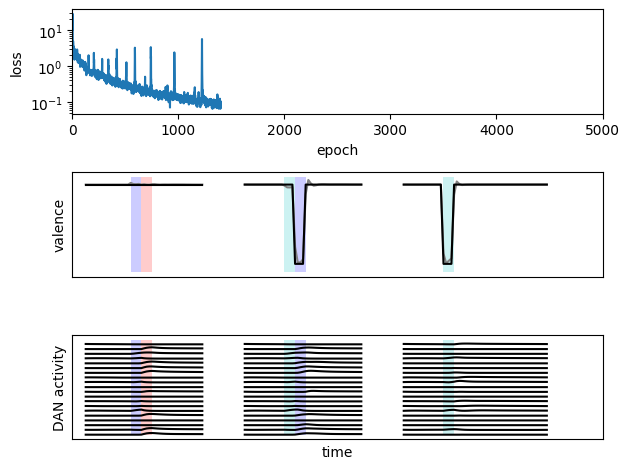

28%,  56.94 seconds

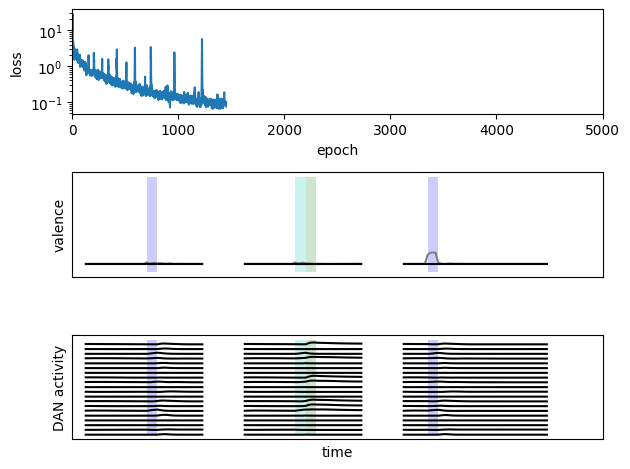

29%,  52.03 seconds

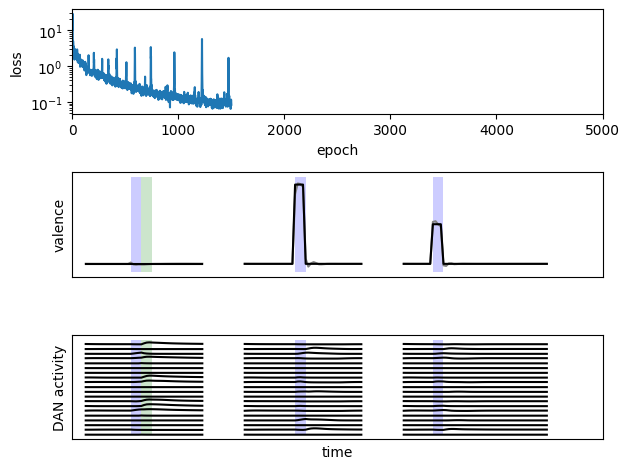

30%,  57.69 seconds

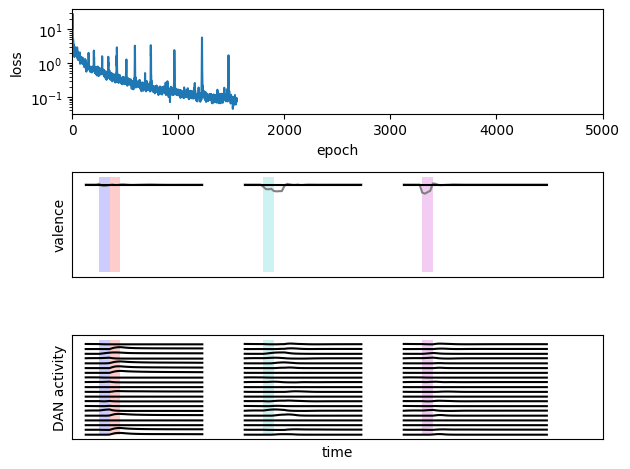

31%,  55.12 seconds

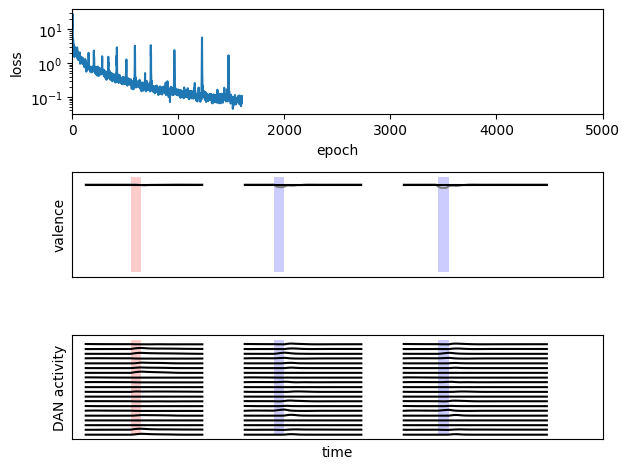

32%,  60.25 seconds

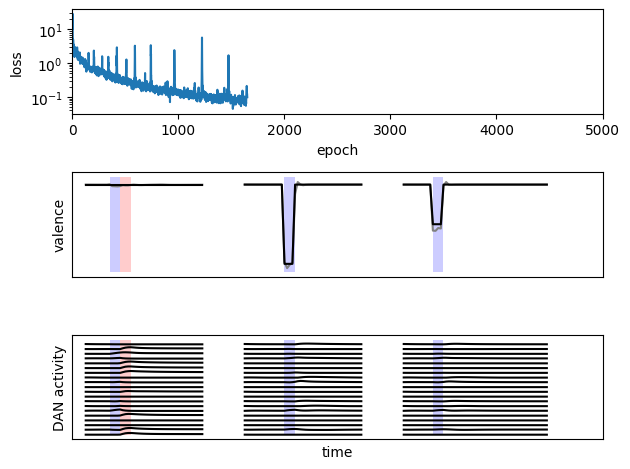

33%,  52.22 seconds

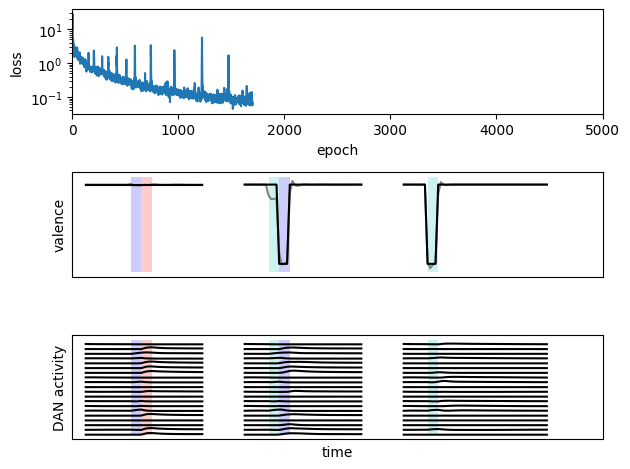

34%,  54.37 seconds

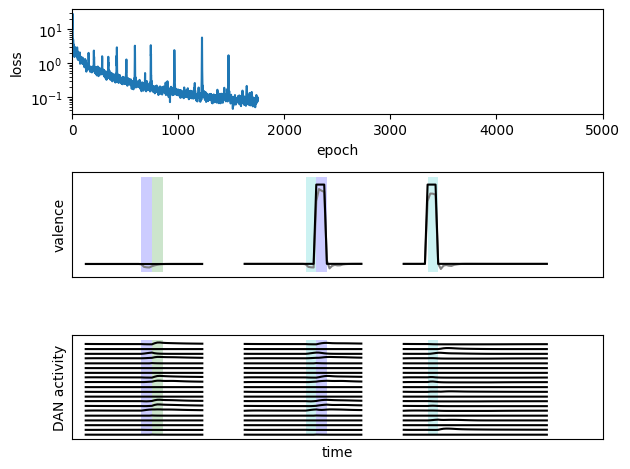

35%,  53.12 seconds

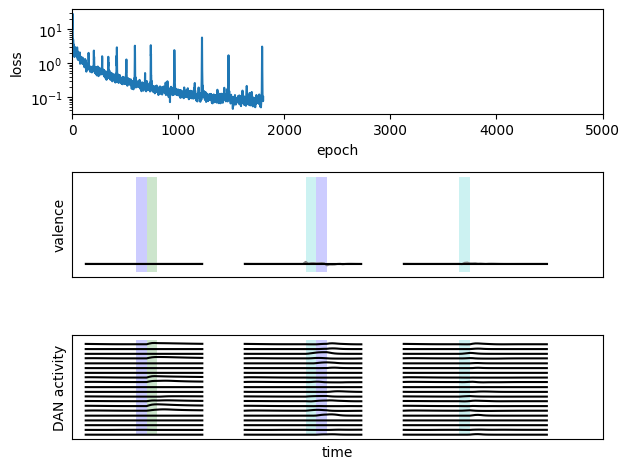

36%,  51.46 seconds

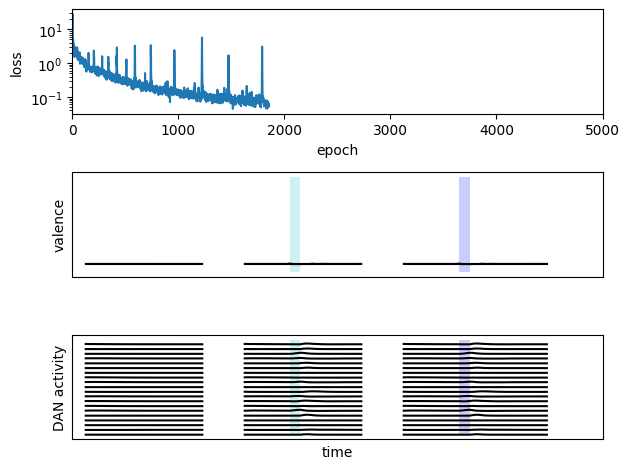

37%,  57.9 seconds

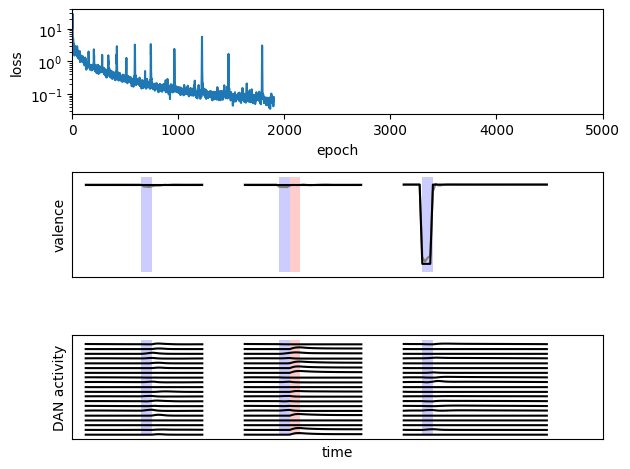

38%,  52.76 seconds

KeyboardInterrupt: 

<Figure size 640x480 with 0 Axes>

In [5]:
from pathlib import Path

assert Path("train.py").is_file(), "Run this cell from the repository root."
%run -i train.py

In [3]:
%matplotlib inline
from IPython.display import display

display(plt.gcf())

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [2]:
globals()

{'__name__': '__main__',
 '__doc__': 'Automatically created module for IPython interactive environment',
 '__package__': None,
 '__loader__': None,
 '__spec__': None,
 '__builtin__': <module 'builtins' (built-in)>,
 '__builtins__': <module 'builtins' (built-in)>,
 '_ih': ['',
  'from pathlib import Path\n\nassert Path("train.py").is_file(), "Run this cell from the repository root."\nget_ipython().run_line_magic(\'run\', \'-i train.py\')',
  'globals()'],
 '_oh': {},
 '_dh': [WindowsPath('c:/Users/Bruna/Documents/GitHub/jiang_litwin-kumar_mb_rnn')],
 'In': ['',
  'from pathlib import Path\n\nassert Path("train.py").is_file(), "Run this cell from the repository root."\nget_ipython().run_line_magic(\'run\', \'-i train.py\')',
  'globals()'],
 'Out': {},
 'get_ipython': <bound method InteractiveShell.get_ipython of <ipykernel.zmqshell.ZMQInteractiveShell object at 0x0000029942403410>>,
 'exit': <IPython.core.autocall.ZMQExitAutocall at 0x2994244ad50>,
 'quit': <IPython.core.autocall.ZMQExi